# Анализ маркетплейса 
Автор: Алексей Булычев

Дата: 2026-10-14

Цель: когортный анализ, retention, PMF, продуктовые метрики, ICE-приоритизация гипотез.

Стек: Python, pandas, numpy, plotly.

Проект реализован в рамках учебного модуля по продуктовой аналитике онлайн-курса "Аналитик данных" от karpov.courses

## Содержание

1. [Описание набора данных](#data-description)
2. [Легенда](#legend)
3. [Разведочный анализ данных](#eda)
4. [Задача 1. Когортный анализ retention](#task-1)
5. [Задача 2. Product/market fit](#task-2)
6. [Задача 3. Пять ключевых продуктовых метрик](#task-3)
7. [Задача 4. Выбор гипотезы через фреймворк ICE](#task-4)
8. [Задача 5. Метрики для A/B-теста](#task-5)
9. [Задача 6. Выводы и отчёт](#task-6)

<a name="data-description"></a>
## Описание набора данных

Общедоступный набор данных о заказах, оформленных в бразильском интернет-магазине Olist Store. Набор данных содержит информацию о 100 000 заказов, оформленных с 2016 по 2018 год на различных бразильских торговых площадках. Он позволяет просматривать заказы по нескольким параметрам: от статуса заказа, цены, оплаты и доставки до местоположения клиента, характеристик товара и, наконец, отзывов покупателей. 

Это реальные коммерческие данные, они анонимизированы, а ссылки на компании и партнеров в тексте обзора заменены названиями великих домов из «Игры престолов».

**Исходный набор данных содержит**:
- olist_customers_dataset.csv
- olist_geolocation_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_orders_dataset.csv
- olist_products_dataset.csv
- olist_sellers_dataset.csv
- product_category_name_translation.csv

В данном проекте используются только 3 из 9 таблиц:
- olist_customers_dataset.csv
- olist_orders_dataset.csv
- olist_order_items_dataset.csv

Подробнее о полном наборе данных: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

<a name="legend"></a>
## Легенда

Стартап, который создает новый маркетплейс. Он недавно появился на рынке и занимается продажей новых товаров из Бразилии, которые только начинают поступать в продажу.

Проблема: выручка маркетплейса стоит на месте уже несколько месяцев.



Список задач:
- Задача 1: Оценить месячный **retention в оформление заказа** с помощью когортного анализа.
- Задача 2: Определить, существует ли product/market fit у этого маркетплейса.
- Задача 3: Определить 5 основных метрик, на которых продакту можно сконцентрироваться, чтобы максимизировать прибыль компании.
- Задача 4: Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.
- Задача 5: Сформулировать нужные метрики, на которые ваша гипотеза должна повлиять.
- Задача 6: Сформулировать выводы о проделанной работе и составить отчет.

In [1]:
# Импорт библиотек

import pandas as pd
import numpy as np
from operator import attrgetter
from dateutil import parser
import matplotlib.pylab as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from tabulate import tabulate



<a name="eda"></a>
## Разведочный анализ данных

In [2]:
# Чтение таблиц

customers = pd.read_csv('data/olist_customers_dataset.csv')
orders = pd.read_csv('data/olist_orders_dataset.csv')
order_items = pd.read_csv('data/olist_order_items_dataset.csv')


In [3]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


У нас есть 2 id покупателя:
- customer_id — позаказный идентификатор пользователя
- customer_unique_id — уникальный идентификатор пользователя (аналог номера паспорта)

In [4]:
# Смотрим пропущенные значения
customers.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [5]:
# Смотрим общее количество покупателей
customers.customer_unique_id.nunique()

96096

In [6]:
# Кол-во штатов
customers.customer_state.nunique()

27

In [7]:
# Распределение покупателей по штатам с сортировкой по убыванию
customers.groupby('customer_state').customer_unique_id.nunique().sort_values(ascending=False)

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
PE     1609
CE     1313
PA      949
MT      876
MA      726
MS      694
PB      519
PI      482
RN      474
AL      401
SE      342
TO      273
RO      240
AM      143
AC       77
AP       67
RR       45
Name: customer_unique_id, dtype: int64

In [8]:
# Кол-во городов
customers.customer_city.nunique()

4119

In [9]:
# Распределение покупателей по городам. Сортировка по убыванию
customers.groupby('customer_city').customer_unique_id.nunique().sort_values(ascending=False)

customer_city
sao paulo         14984
rio de janeiro     6620
belo horizonte     2672
brasilia           2069
curitiba           1465
                  ...  
pedranopolis          1
pedrao                1
matias olimpio        1
pedras altas          1
capela nova           1
Name: customer_unique_id, Length: 4119, dtype: int64

In [10]:
# Покупатели сгруппированнвые по штатам и городам одновременно. Сортировка по убыванию
customers.groupby(['customer_state', 'customer_city']).customer_unique_id.nunique().sort_values(ascending=False)

customer_state  customer_city 
SP              sao paulo         14984
RJ              rio de janeiro     6620
MG              belo horizonte     2672
DF              brasilia           2069
PR              curitiba           1465
                                  ...  
TO              pequizeiro            1
                peixe                 1
                novo jardim           1
                novo alegre           1
                nova olinda           1
Name: customer_unique_id, Length: 4310, dtype: int64

In [11]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [12]:
# Проверяем пропуски
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

- order_approved_at — время подтверждения оплаты заказа
- order_delivered_carrier_date — время передачи заказа в логистическую службу
- order_delivered_customer_date — время доставки заказа

имеют пропуски, т.к. судя по всему не все заказы были оплачены, переданы на доставку и доставлены


In [13]:
# Смотрим типы данных
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Всем переменным, содержащим дату и время, необходимо задать корректный тип данных Timestamp

- order_purchase_timestamp
- order_approved_at
- order_delivered_carrier_date
- order_delivered_customer_date
- order_estimated_delivery_date

In [14]:
# Перевод столбцов из str в datetime64
cols_str_to_dt = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]

orders[cols_str_to_dt] = orders[cols_str_to_dt].apply(pd.to_datetime)
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

<a name="task-1"></a>
## Задача 1. Оценить месячный retention в оформление заказа с помощью когортного анализа.

На первом этапе посмотреть на метрики маркетплейса и на возвращаемость клиента в продукт.

Для этого нужно:

Оценить месячный retention в оформление заказа с помощью когортного анализа, так как важно, чтобы клиенты возвращались в маркетплейс для совершения больших покупок.

В рамках исследования необходимо:

- Исследовать датасет и определить, какой вид заказа будет учитываться в retention
- Построить месячный retention
- Проанализировать, чему равен медианный retention 1-го месяца (т.е. взять retention 1-ого месяца для всех когорт и посчитать по этим числам медиану)
- Найти когорту с самым высоким retention на 3-й месяц.
- Проиллюстрировать результаты релевантной визуализацией, удобной для восприятия.

In [15]:
# Кол-во заказов по статусам
orders.groupby('order_status').order_id.nunique()

order_status
approved           2
canceled         625
created            5
delivered      96478
invoiced         314
processing       301
shipped         1107
unavailable      609
Name: order_id, dtype: int64


Для дальнейшего расчета Retention буду использовать только доставленные заказы со статусом delivered, то есть завершенные. Потому что мы имеем дело с маркетплейсом и наша задача оценить возвращаемость к повторным покупкам (в нашем случае доставленным заказам), а не возвращаемость в другие действия, связанные с заказом. 

Если в расчет включить все статусы заказов, то это была бы скорее оценка удержания в общей активности с заказом или попытках заказать, а не по факту повторного получения ценности от продукта. Ценность маркетплейса как продукта для потребителя состоит в успешном приобретении товара. Удержанным в данном случае является тот покупатель, который совершил покупку (имеет статус заказа delivered) и снова возвращается за новыми успешными (т.е. завершенным) покупками. Если в расчет включить все статусы заказов, то мы будем оценивать их возвращаемость, например, в том числе и в отмену заказов, что не является удержанием, а скорее наоборот. Если отмену заказа считать удержанием, то это завысит Retention при, возможно, плохом пользовательском опыте из-за которого происходит отмена или пользователь вообще не доходит до этого шага и его заказ остается незавершенным (любой статус &#8800; delivered)

In [16]:
# Создаю столбец с годом и месяцем для месячного retention
orders['order_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

Выше использую именно order_purchase_timestamp — время создания заказа, а не order_delivered_customer_date — время доставки заказа, т.к. пользователь возвращается именно во время создания заказа. Время доставки же зависит от логистики, а не действий пользователя.

In [17]:
# Отбираю заказы со статусом delivered
orders_delivered = orders[orders['order_status'] == 'delivered']

In [18]:
customers.columns.tolist()

['customer_id',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state']

In [19]:
# Объединение таблиц для получения уникальных id покупателей

orders_delivered_merged = orders_delivered.merge(customers[['customer_id', 'customer_unique_id']],
                                                 on='customer_id',
                                                 how='left')

In [20]:
# Проверка на пропуски после объединения
orders_delivered_merged.isna().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
order_month                       0
customer_unique_id                0
dtype: int64

Когортный анализ

In [21]:
# Создаю копию данных
data_copy = orders_delivered_merged.copy()

# Извлекаю день заказа
data_copy['order_period_day'] = data_copy['order_purchase_timestamp'].dt.to_period('D')

data_copy['cohort'] = data_copy.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')
data_copy['cohort_day'] = data_copy.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('D')

# Рассчитываю номер периода для каждого заказа (один период = 30 дней): 
# разница момента создания текущего заказа и момента первого создания заказа
# разделенная на 30 и округленная вниз
data_copy['period_number_month'] = np.floor((data_copy.order_period_day - data_copy.cohort_day).apply(attrgetter('n'))/30)

# Агрегирую данные по месячным когортам и номеру периода в месяцах
# Для каждой когорты считается количество уникальных покупателей
df_cohort = data_copy.groupby(['cohort', 'period_number_month']).agg(n_customers=('customer_unique_id', 'nunique')).reset_index()

# Сводная таблица
cohort_pivot = df_cohort.pivot_table(index='cohort', columns='period_number_month', values='n_customers')

# Расчет размера когорт - выбор данных за счет iloc по позиции [все строки :, первого столбца, т.е. с индексом 0]
cohort_size = cohort_pivot.iloc[:, 0]

# Делю каждое значение на размер его когорты, чтобы получить расчет в долях
retention_matrix = cohort_pivot.divide(cohort_size, axis=0)


In [22]:
cohort_pivot

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,...,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,1.0,1.0
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,NaN,4.0,1.0,1.0,2.0,2.0,NaN,NaN,...,4.0,3.0,2.0,NaN,2.0,2.0,2.0,1.0,NaN,NaN
2017-02,1628.0,2.0,3.0,6.0,4.0,2.0,4.0,1.0,2.0,4.0,...,6.0,1.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN,NaN
2017-03,2503.0,7.0,13.0,11.0,3.0,2.0,9.0,4.0,6.0,6.0,...,4.0,4.0,3.0,7.0,2.0,3.0,2.0,NaN,NaN,NaN
2017-04,2256.0,8.0,6.0,1.0,6.0,8.0,6.0,10.0,5.0,6.0,...,3.0,NaN,2.0,2.0,2.0,2.0,NaN,NaN,NaN,NaN
2017-05,3451.0,14.0,14.0,8.0,13.0,11.0,11.0,4.0,10.0,9.0,...,11.0,6.0,3.0,7.0,4.0,NaN,NaN,NaN,NaN,NaN
2017-06,3037.0,13.0,15.0,11.0,5.0,16.0,9.0,6.0,4.0,10.0,...,9.0,3.0,9.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
retention_matrix

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.003817,NaN,NaN,0.003817,...,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,0.007634,0.003817,0.003817
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.002789,NaN,0.005579,0.001395,0.001395,0.002789,0.002789,NaN,NaN,...,0.005579,0.004184,0.002789,NaN,0.002789,0.002789,0.002789,0.001395,NaN,NaN
2017-02,1.0,0.001229,0.001843,0.003686,0.002457,0.001229,0.002457,0.000614,0.001229,0.002457,...,0.003686,0.000614,0.001843,0.001229,0.000614,0.000614,0.001843,NaN,NaN,NaN
2017-03,1.0,0.002797,0.005194,0.004395,0.001199,0.000799,0.003596,0.001598,0.002397,0.002397,...,0.001598,0.001598,0.001199,0.002797,0.000799,0.001199,0.000799,NaN,NaN,NaN
2017-04,1.0,0.003546,0.002660,0.000443,0.002660,0.003546,0.002660,0.004433,0.002216,0.002660,...,0.001330,NaN,0.000887,0.000887,0.000887,0.000887,NaN,NaN,NaN,NaN
2017-05,1.0,0.004057,0.004057,0.002318,0.003767,0.003187,0.003187,0.001159,0.002898,0.002608,...,0.003187,0.001739,0.000869,0.002028,0.001159,NaN,NaN,NaN,NaN,NaN
2017-06,1.0,0.004281,0.004939,0.003622,0.001646,0.005268,0.002963,0.001976,0.001317,0.003293,...,0.002963,0.000988,0.002963,0.001317,NaN,NaN,NaN,NaN,NaN,NaN


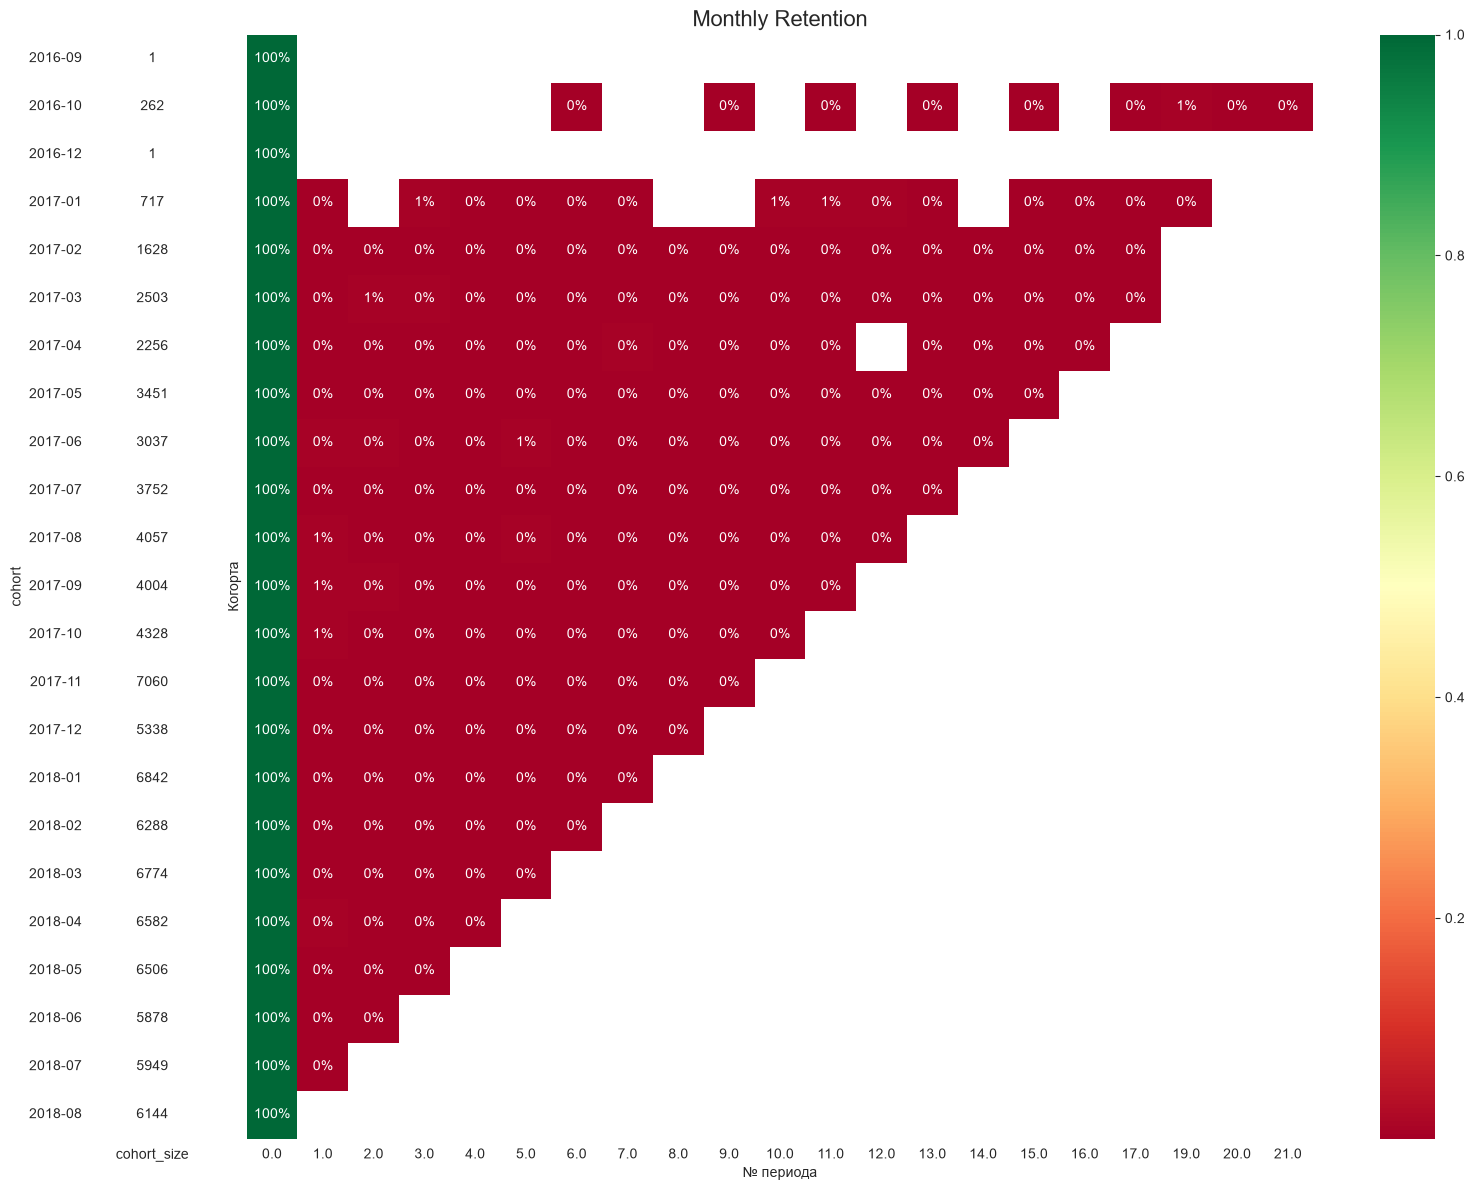

In [24]:
# Строим тепловую карту когортного анализа
with sns.axes_style("white"):
    fig, ax = plt.subplots(1, 2, figsize=(16, 12), sharey=True, gridspec_kw={'width_ratios': [1, 11]})

    # Тепловая карта для коэффициентов удержания
    sns.heatmap(retention_matrix,
                mask=retention_matrix.isnull(),
                annot=True,
                fmt='.0%',
                cmap='RdYlGn',
                ax=ax[1])
    ax[1].set_title('Monthly Retention', fontsize=16)
    ax[1].set(xlabel='№ периода', ylabel='Когорта')

    # Тепловая карта для размеров когорт
    cohort_size_df = pd.DataFrame(cohort_size).rename(columns={0: 'cohort_size'})
    white_cmap = mcolors.ListedColormap(['white'])
    sns.heatmap(cohort_size_df,
                annot=True,
                cbar=False,
                fmt='g',
                cmap=white_cmap,
                ax=ax[0])

    fig.tight_layout()
    plt.show()

По заданию также нужно

- Проанализировать, чему равен медианный retention 1-го месяца (т.е. взять retention 1-ого месяца для всех когорт и посчитать по этим числам медиану)
- Найти когорту с самым высоким retention на 3-й месяц.
- Проиллюстрировать результаты релевантной визуализацией, удобной для восприятия.

In [25]:
# Усреднённый retention за первый месяц
avg_retention_first_month = retention_matrix[1].median()
avg_retention_second_month = retention_matrix[2].median()
print(f'Медианный retention за первый месяц: {avg_retention_first_month *100:.2f}%')
print(f'Медианный retention за второй месяц: {avg_retention_second_month *100:.2f}%')

Медианный retention за первый месяц: 0.35%
Медианный retention за второй месяц: 0.27%


In [26]:
median_retention = retention_matrix.median()

for period, value in median_retention.items():
    print(f'Медианный retention за {period}-й период: {value:.2%}')

Медианный retention за 0.0-й период: 100.00%
Медианный retention за 1.0-й период: 0.35%
Медианный retention за 2.0-й период: 0.27%
Медианный retention за 3.0-й период: 0.24%
Медианный retention за 4.0-й период: 0.24%
Медианный retention за 5.0-й период: 0.19%
Медианный retention за 6.0-й период: 0.27%
Медианный retention за 7.0-й период: 0.18%
Медианный retention за 8.0-й период: 0.15%
Медианный retention за 9.0-й период: 0.25%
Медианный retention за 10.0-й период: 0.20%
Медианный retention за 11.0-й период: 0.27%
Медианный retention за 12.0-й период: 0.16%
Медианный retention за 13.0-й период: 0.19%
Медианный retention за 14.0-й период: 0.13%
Медианный retention за 15.0-й период: 0.10%
Медианный retention за 16.0-й период: 0.10%
Медианный retention за 17.0-й период: 0.23%
Медианный retention за 19.0-й период: 0.45%
Медианный retention за 20.0-й период: 0.38%
Медианный retention за 21.0-й период: 0.38%


In [27]:
highest_retention_value = retention_matrix[3].max()
highest_retention_third_month = retention_matrix[3].idxmax()

print(f'Когорта с самым высоким retention на третий месяц: {highest_retention_third_month}, значение: {highest_retention_value *100:.2f}%')

Когорта с самым высоким retention на третий месяц: 2017-01, значение: 0.56%



<a name="task-2"></a>
## Задача 2. Определить, существует ли product/market fit у этого маркетплейса.

- Оценить наличие product/market fit у данного продукта с помощью когортного анализа, полученного на предыдущем шаге.
- Пояснить свою позицию и сформулировать, на чём маркетплейс должен сконцентрироваться в ближайшее время. Если PMF есть, то в какую сторону лучше развивать продукт дальше? Если PMF нет, то какие причины могут быть у этого?
- Подкрепить свои выводы релевантной визуализацией, удобной для восприятия.

In [28]:
cohort_size

cohort
2016-09       1.0
2016-10     262.0
2016-12       1.0
2017-01     717.0
2017-02    1628.0
2017-03    2503.0
2017-04    2256.0
2017-05    3451.0
2017-06    3037.0
2017-07    3752.0
2017-08    4057.0
2017-09    4004.0
2017-10    4328.0
2017-11    7060.0
2017-12    5338.0
2018-01    6842.0
2018-02    6288.0
2018-03    6774.0
2018-04    6582.0
2018-05    6506.0
2018-06    5878.0
2018-07    5949.0
2018-08    6144.0
Freq: M, Name: 0.0, dtype: float64

In [29]:
cohort_size.describe()

count      23.000000
mean     4059.043478
std      2393.119066
min         1.000000
25%      2379.500000
50%      4057.000000
75%      6216.000000
max      7060.000000
Name: 0.0, dtype: float64

In [30]:

median_cohort_size = cohort_size.median()
print(f'Маркетплейс в среднем каждый месяц привлекает {median_cohort_size:.0f} новых покупателей')

Маркетплейс в среднем каждый месяц привлекает 4057 новых покупателей


**Ответ на задачу 2:**

По результатам когортного анализа маркетплейс успешно привлекает новых покупателей. Медианное значение составляет 4057 клиентов в месяц. 

Однако продукт имеет низкий показатель удержания (Retention). После привлечения клиентов их медианный показатель удержания в первый месяц пользования продуктом составляет 0.35% и на протяжений всех последущих месяцев не поднимается выше 1%. Это свидетельствует о том, что пользователи проявляют интерес к продукту, но после знакомства с ним уходят на ранней стадии. Это может говорить о проблемах с самим маркетплейсом, его функциональностью, ассортиментом или качеством сервиса. При изначально высоких цифрах привлечения пользователи не находят ценности в продукте - product/market fit низкий. Продукт требует доработок.


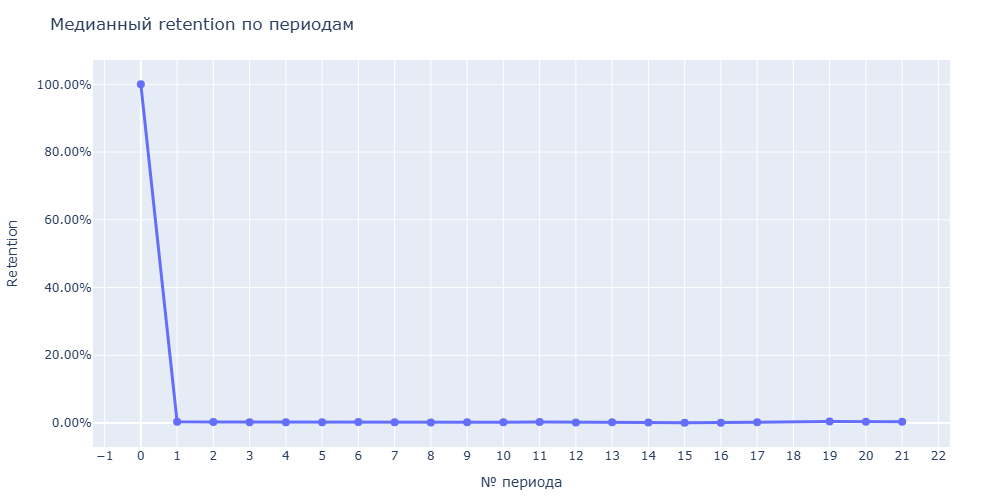

In [31]:
# Интерактивный график Plotly
median_retention = retention_matrix.median().reset_index()
median_retention.columns = ['period', 'retention']

fig = px.line(
    median_retention,
    x='period',
    y='retention',
    markers=True,
    title='Медианный retention по периодам',
    labels={'period': '№ периода', 'retention': 'Retention'},
)

fig.update_yaxes(tickformat='.2%')
fig.update_xaxes(dtick=1)
fig.update_traces(line=dict(width=3), marker=dict(size=8))

# Задаем единый размер для самой фигуры (для обоих вариантов)
fig.update_layout(
    autosize=False,
    width=1000,     # ширина
    height=500,     # высота
    margin=dict(l=50, r=50, t=60, b=50) # отступы
)

# Интерактивный график
fig.show()

# Статичный график для GitHub
fig.show("png")

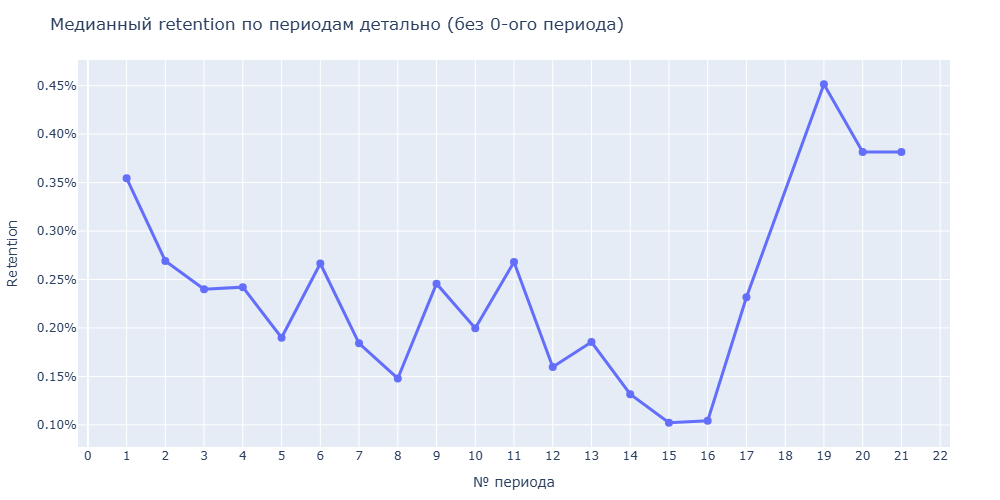

In [32]:
# Интерактивный график Plotly (без 0-ого периода)
median_retention = retention_matrix.drop(columns=[0]).median().reset_index()
median_retention.columns = ['period', 'retention']

fig = px.line(
    median_retention,
    x='period',
    y='retention',
    markers=True,
    title='Медианный retention по периодам детально (без 0-ого периода)',
    labels={'period': '№ периода', 'retention': 'Retention'},
)

fig.update_yaxes(tickformat='.2%')
fig.update_xaxes(dtick=1)  # заставляет показать все периоды

fig.update_traces(line=dict(width=3), marker=dict(size=8))

# Задаем единый размер для самой фигуры (для обоих вариантов)
fig.update_layout(
    autosize=False,
    width=1000,     
    height=500,     
    margin=dict(l=50, r=50, t=60, b=50) 
)

# Выводим интерактивный график
fig.show()

# Выводим статичный график для корректного отображения на GitHub
fig.show("png")

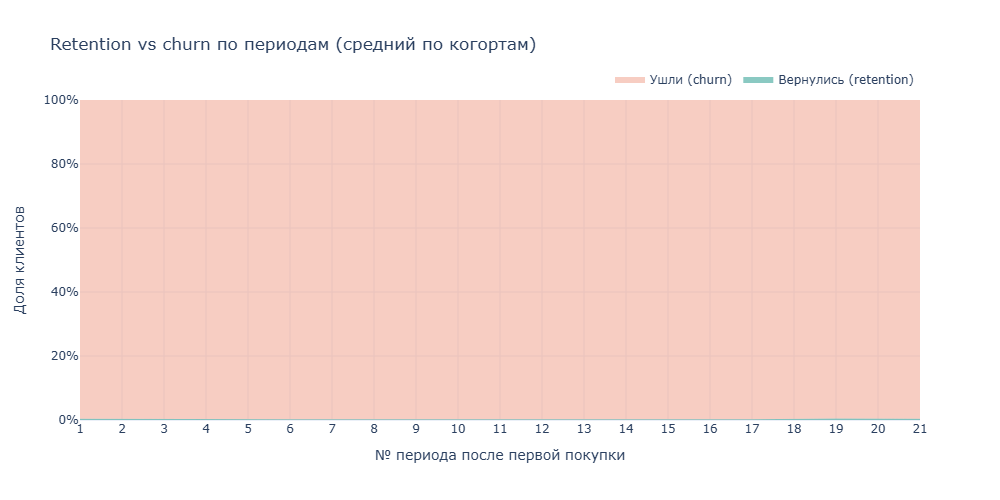

In [33]:


# Средний retention по когортам, без 0-го периода
mean_retention = retention_matrix.drop(columns=[0]).mean()

# Churn = 1 - retention
churn = 1 - mean_retention

# Строим stacked area
fig = go.Figure()

# нижний слой — вернувшиеся
fig.add_trace(go.Scatter(
    x=mean_retention.index,
    y=mean_retention.values,
    name='Вернулись (retention)',
    mode='lines',
    line=dict(width=0, color='#2a9d8f'),
    fillcolor='rgba(42,157,143,0.55)',
    stackgroup='one',
    hovertemplate='Период %{x}<br>Вернулись: %{y:.2%}<extra></extra>',
))

# верхний слой — ушедшие, рисуется поверх нижнего
fig.add_trace(go.Scatter(
    x=churn.index,
    y=churn.values,
    name='Ушли (churn)',
    mode='lines',
    line=dict(width=0, color='#e76f51'),
    fillcolor='rgba(231,111,81,0.35)',
    stackgroup='one',
    hovertemplate='Период %{x}<br>Ушли: %{y:.2%}<extra></extra>',
))

# Оформление
fig.update_layout(
    title='Retention vs churn по периодам (средний по когортам)',
    xaxis_title='№ периода после первой покупки',
    yaxis_title='Доля клиентов',
    template='plotly_white',
    hovermode='x unified',
    width=1000, 
    height=500,
    autosize=False, # Жестко фиксируем размер
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
)

fig.update_yaxes(tickformat='.0%', range=[0, 1])
fig.update_xaxes(dtick=1)

# Выводим интерактивный график
fig.show()

# Выводим статичный график для корректного отображения на GitHub
fig.show("png")

<a name="task-3"></a>
## Задача 3. Определить 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.

Вы разобрались с наличием product/market fit. Теперь вас просят сформулировать продуктовые метрики маркетплейса, чтобы компания могла на них ориентироваться.

В первую очередь необходимо:

Определить 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.

- Первая метрика должна отражать рост объёма продаж маркетплейса.
- Вторая — показывать объем аудитории, которой продукт доставляет ценность.
- Третья — отражать заинтересованность новых клиентов в продукте (даже если вы не можете посчитать ее на имеющихся у вас данных).
- Четвёртая — отражать вовлеченность клиента в продолжение использования продукта.
- Пятая — отражать денежное выражение вовлеченности клиента.

Визуализируйте первую, вторую, четвёртую и пятую метрики. Используйте месячную гранулярность и окно в 1 месяц, если это нужно.

In [34]:
gmv_data = orders_delivered.merge(order_items[['order_id', 'price']], on='order_id')

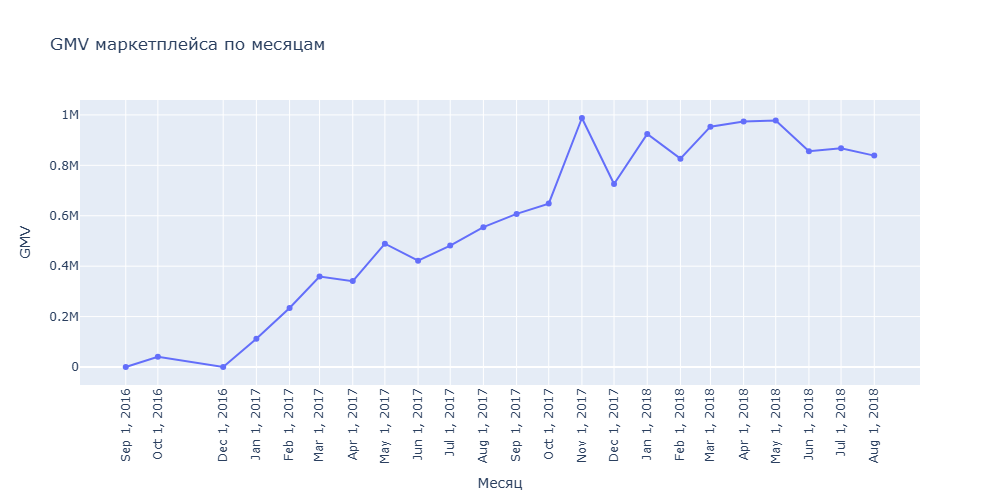

In [35]:
monthly_gmv = gmv_data.groupby('order_month')['price'].sum().reset_index()
monthly_gmv['order_month'] = monthly_gmv['order_month'].astype(str)
monthly_gmv.columns = ['order_month', 'GMV']

fig = px.line(
    monthly_gmv,
    x='order_month',
    y='GMV',
    markers=True,
    title='GMV маркетплейса по месяцам',
    labels={'order_month': 'Месяц', 'GMV': 'GMV'} # Немного поправил ключ, чтобы точно совпадал с колонкой
)

# Задаем единый размер для фигуры
fig.update_layout(
    xaxis_tickangle=-45, 
    hovermode='x unified',
    width=1000, 
    height=500,
    autosize=False  # Отключаем автоподстройку под окно
)

fig.update_xaxes(
    tickmode='array',
    tickvals=monthly_gmv['order_month'],
    tickangle=-90
)

# 1. Выводим интерактивный график
fig.show()

# 2. Выводим статичный график для GitHub
fig.show("png")

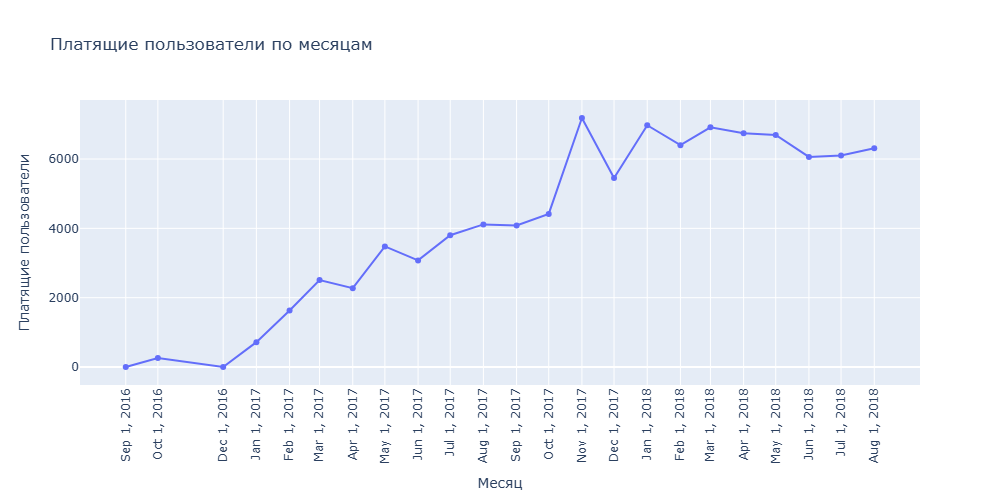

In [36]:
paying_users = orders_delivered_merged.groupby(orders_delivered_merged['order_month']).customer_unique_id.nunique().reset_index()
paying_users['order_month'] = paying_users['order_month'].astype(str)
paying_users.columns = ['order_month', 'paying_users']

fig = px.line(
    paying_users,
    x='order_month',
    y='paying_users',
    markers=True,
    title='Платящие пользователи по месяцам',
    labels={'order_month': 'Месяц', 'paying_users': 'Платящие пользователи'}
)

# Задаем единый размер и оформление
fig.update_layout(
    xaxis_tickangle=-90,
    hovermode='x unified',
    width=1000,     # Фиксированная ширина
    height=500,     # Фиксированная высота
    autosize=False  # Отключаем автоподстройку
)

fig.update_xaxes(
    tickmode='array',
    tickvals=paying_users['order_month']
)

# 1. Выводим интерактивный график
fig.show()

# 2. Выводим статичный график для GitHub
fig.show("png")

In [37]:
# Объединяем с таблицей клиентов для получения customer_unique_id
order_all_info = gmv_data.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')

monthly_revenue = order_all_info.groupby('order_month').agg(
    total_revenue=('price', 'sum'),
    paying_users=('customer_unique_id', 'nunique')).reset_index()

monthly_revenue['ARPPU'] = monthly_revenue['total_revenue'] / monthly_revenue['paying_users']

monthly_revenue[['order_month', 'total_revenue', 'paying_users', 'ARPPU']]

,order_month,total_revenue,paying_users,ARPPU
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,262,153.912634
2,2016-12,10.90,1,10.900000
3,2017-01,111798.36,718,155.708022
4,2017-02,234223.40,1630,143.695337
5,2017-03,359198.85,2508,143.221232
6,2017-04,340669.68,2274,149.810765
7,2017-05,489338.25,3479,140.654858
8,2017-06,421923.37,3076,137.166245
9,2017-07,481604.52,3802,126.671362


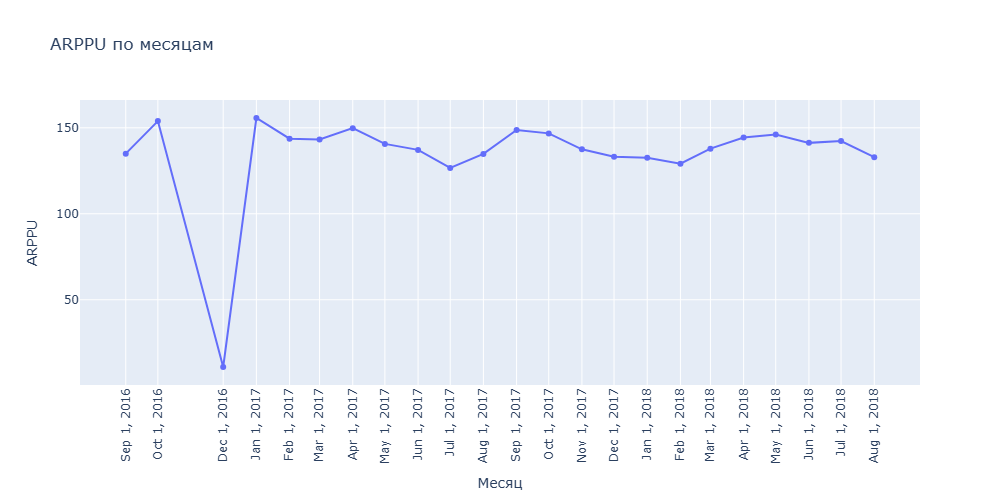

In [38]:
monthly_revenue['order_month'] = monthly_revenue['order_month'].astype(str)

fig = px.line(
    monthly_revenue,
    x='order_month',
    y='ARPPU',
    markers=True,
    title='ARPPU по месяцам',
    labels={'order_month': 'Месяц', 'ARPPU': 'ARPPU'}
)

# Задаем единый размер и оформление
fig.update_layout(
    xaxis_tickangle=-90,
    hovermode='x unified',
    width=1000,     # Фиксированная ширина
    height=500,     # Фиксированная высота
    autosize=False  # Отключаем автоподстройку
)

fig.update_xaxes(
    tickmode='array',
    tickvals=monthly_revenue['order_month']
)

fig.update_traces(
    hovertemplate='%{x}<br>ARPPU: %{y:.2f}<extra></extra>'
)

# 1. Выводим интерактивный график
fig.show()

# 2. Выводим статичный график для GitHub
fig.show("png")

<a name="task-4"></a>
## Задача 4. Выбрать одну из 3-х основных гипотез с помощью фреймворка ICE.

| Гипотеза | Impact | Confidence | Ease | ICE |
| --- | --- | --- | --- | --- |
| Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен. | - | 8 | 6 | - |
| Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счёт повторных заказов. | - | 10 | 4 | - |
| Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при оформлении заказа, вследствие чего количество заказов увеличится за счёт повторных заказов тех, кто раньше не делал повторный заказ. | - | 5 | 9 | - |

По заданию Confidence и Ease уже даны и рассчитаны командой. Необходимо рассчитать Impact на данных начиная с июня 2017 года. Считать, что конверсия в повторный заказ равна величине медианного retention 1-го месяца (см. пункт 1 проекта: avg_retention_first_month).

Шкала для перевода метрики Impact

| Impact | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Значение метрики | 0 - 50 | 51 - 150 | 151 - 350 | 351 - 750 | 751 - 1550 | 1551 - 3150 | 3151 - 6350 | 6351 - 12750 | 12751 - 25550 | 25551 - 51 150 |

**Гипотеза 1. Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен.**

Для расчёта Impact по этой гипотезе посчитаем кол-во заказов со статусами отмены:
- unavailable — заказ отменён по причине недоступности товара
- canceled — отменён

In [39]:
# По заданию нам нужны данные с июня 2017

orders[orders.order_month >= '2017-06'].groupby('order_status').order_id.nunique()

order_status
canceled         499
created            5
delivered      85413
invoiced         240
processing       202
shipped          912
unavailable      475
Name: order_id, dtype: int64

In [40]:
count_canceled = orders[(orders.order_month >= '2017-06') &
                        orders.order_status.isin(['canceled', 'unavailable'])].order_id.nunique()
count_canceled

print(f'Количество отменённых заказов: {count_canceled}')

Количество отменённых заказов: 974


**Гипотеза 2. Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счёт повторных заказов.**

Для рассчёта Impact по этой гипотезе можно посчитать кол-во заказов, которые были доставлены позже обещанной даты 

order_delivered_customer_date > order_estimated_delivery_date

avg_retention_first_month - принимается за конверсию в повторные заказы

In [41]:
# Проверяем типы данных
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
order_month                           period[M]
dtype: object

In [42]:
count_delayed = orders[(orders.order_month >= '2017-06') & (orders.order_delivered_customer_date > orders.order_estimated_delivery_date)
                      & (orders.order_status.isin(['delivered']))].order_id.nunique()

print(f'Количество задержанных заказов: {count_delayed}')

Количество задержанных заказов: 7295


In [43]:
print(f'Возможное количество повторных заказов: {round(count_delayed*avg_retention_first_month, 2)}')

Возможное количество повторных заказов: 25.87


**Гипотеза 3. Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при оформлении заказа, вследствие чего количество заказов увеличится за счёт повторных заказов тех, кто раньше не делал повторный заказ.**

Можно посчитать количество клиентов, которые сделали только один заказ на маркетплейсе

avg_retention_first_month - принимается за конверсию в повторные заказы

In [44]:
customer_order_count = orders_delivered_merged[(orders_delivered_merged.order_month >= '2017-06')].groupby('customer_unique_id').order_id.nunique().reset_index()

single_order_customer_count = (customer_order_count == 1).order_id.sum()


In [45]:
customer_order_count.groupby('order_id').nunique('customer_unique_id')

,customer_unique_id
order_id,
1,80558
2,2137
3,129
4,23
5,9
6,2
7,3
9,1
15,1


In [46]:
print(f'Количество покупателей, сделавших только один заказ: {single_order_customer_count}')

Количество покупателей, сделавших только один заказ: 80558


In [47]:
print(f'Возможное количество повторных заказов: {round(single_order_customer_count*avg_retention_first_month, 2)}')

Возможное количество повторных заказов: 285.67


In [48]:
# ---------------------------------------------------------------
# 1. Функция перевода метрики в Impact по шкале 1–10
# ---------------------------------------------------------------
def metric_to_impact(value):
    """
    Переводит количественное значение метрики в балл Impact (1–10).

    Шкала:
    1:  0 – 50
    2:  51 – 150
    3:  151 – 350
    4:  351 – 750
    5:  751 – 1550
    6:  1551 – 3150
    7:  3151 – 6350
    8:  6351 – 12750
    9:  12751 – 25550
    10: 25551 – 51150
    Всё, что выше 51150, тоже даёт Impact = 10.
    """
    breaks = [50, 150, 350, 750, 1550, 3150, 6350, 12750, 25550, 51150]
    labels = list(range(1, 11))

    if pd.isna(value):
        return np.nan

    if value > breaks[-1]:
        return 10

    return pd.cut(
        [value],
        bins=[-np.inf] + breaks,
        labels=labels,
        right=True
    )[0].astype(int)


# ---------------------------------------------------------------
# 2. Значения метрик по гипотезам
# ---------------------------------------------------------------
# Гипотеза 1: кол-во отменённых заказов (canceled + unavailable) с июня 2017
impact_hypothesis_1 = count_canceled

# Гипотеза 2: кол-во задержанных заказов × retention 1-го месяца
impact_hypothesis_2 = count_delayed * avg_retention_first_month

# Гипотеза 3: кол-во клиентов с единственным заказом × retention 1-го месяца
impact_hypothesis_3 = single_order_customer_count * avg_retention_first_month

# ---------------------------------------------------------------
# 3. Перевод метрик в баллы Impact
# ---------------------------------------------------------------
impact_score_1 = metric_to_impact(impact_hypothesis_1)
impact_score_2 = metric_to_impact(impact_hypothesis_2)
impact_score_3 = metric_to_impact(impact_hypothesis_3)

# ---------------------------------------------------------------
# 4. Confidence и Ease заданы командой
# ---------------------------------------------------------------
confidence = [8, 10, 5]
ease       = [4 if False else 6, 4, 9]   # аккуратно: у 1-й гипотезы Ease = 6

# ---------------------------------------------------------------
# 5. Формируем таблицу и считаем ICE
# ---------------------------------------------------------------
ice_table = pd.DataFrame({
    'Гипотеза': [
        '1. Исправить баг в системе процессинга заказов',
        '2. Сократить время до отгрузки заказа',
        '3. Создать новый способ оплаты'
    ],
    'Значение метрики': [
        round(impact_hypothesis_1, 2),
        round(impact_hypothesis_2, 2),
        round(impact_hypothesis_3, 2)
    ],
    'Impact':     [impact_score_1, impact_score_2, impact_score_3],
    'Confidence': confidence,
    'Ease':       ease,
})

ice_table['ICE'] = ice_table['Impact'] * ice_table['Confidence'] * ice_table['Ease']

# Сортируем по ICE по убыванию — лучшая гипотеза сверху
ice_table = ice_table.sort_values('ICE', ascending=False).reset_index(drop=True)

# ---------------------------------------------------------------
# 6. Вывод таблицы через tabulate
# ---------------------------------------------------------------
print(tabulate(
    ice_table,
    headers='keys',
    tablefmt='pretty',          # можно заменить на 'grid', 'psql', 'pretty', 'fancy_grid', 'github'
    showindex=False,
    colalign=('left', 'right', 'center', 'center', 'center', 'center')
))

# Лучшая гипотеза
best = ice_table.iloc[0]
print(f'\nЛучшая гипотеза по ICE: {best["Гипотеза"]}')
print(f'ICE = {best["ICE"]}')

+------------------------------------------------+------------------+--------+------------+------+-----+
| Гипотеза                                       | Значение метрики | Impact | Confidence | Ease | ICE |
+------------------------------------------------+------------------+--------+------------+------+-----+
| 1. Исправить баг в системе процессинга заказов |            974.0 |   5    |     8      |  6   | 240 |
| 3. Создать новый способ оплаты                 |           285.67 |   3    |     5      |  9   | 135 |
| 2. Сократить время до отгрузки заказа          |            25.87 |   1    |     10     |  4   | 40  |
+------------------------------------------------+------------------+--------+------------+------+-----+

Лучшая гипотеза по ICE: 1. Исправить баг в системе процессинга заказов
ICE = 240


<a name="task-5"></a>
## Задача 5. Сформулировать нужные метрики, на которые ваша гипотеза должна повлиять.

После предыдущего исследования у вас появилась гипотеза, которую можно реализовать для значительного улучшения метрик компании. Вы предложили использовать A/B-тестирование для проверки её эффективности.

Продакт попросил вас:

- Сформулировать метрики, на которые должна повлиять выбранная вами гипотеза.
- Сформулировать хотя бы по одной метрике в категории: целевые, прокси, guardrail и объяснить свой выбор.

Ответ

Лучшая гипотеза по ICE:
Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен.

Целевые метрики: 
- абсолютное количество доставленных заказов - оценить увеличилось ли количество доставленных заказов после исправления бага

Прокси-метрика: 
- конверсия в доставку заказа (количество доставленных заказов / общее количество заказов)
- конверсия в отгрузку (количество shipped / общее количество заказов) - т.к. доставка занимает время и сопряжена с логистикой, то мы можем посмотреть изменение метрики на более ранннем этапе и раньше отследить изменения

Guardrail-метрика:
- конверсия в оформление заказа (клиенты, которые оформили хотя бы один заказ / все пользователи ) - оценить не затронули ли исправления бага переход  к created или approved
- среднее время обработки заказа (среднее время от разицы между временем передачи заказа в логистическую службу и временем подтверждения заказа 
avg(order_delivered_carrier_date  - order_approved_at))

